# Ilha Solteira: vazões mensais, ARIMA e SARIMA
**Projeto reproduzível | 1931–2016 | previsão com intervalos de 95%**

Este notebook acompanha o caminho dos exemplos fornecidos: importar e organizar
os dados, explorar a série, investigar estacionariedade e sazonalidade, ajustar
ARIMA e SARIMA, analisar resíduos e comparar previsões com valores observados.
Corrigimos o período sazonal e a construção dos intervalos dos exemplos.
O documento `docs/como_seguimos_os_exemplos.md` relaciona cada adaptação às páginas.

**Pergunta:** incluir a sazonalidade anual melhora a previsão de vazões mensais?
Vamos responder com validação temporal e teste separado, sem presumir que SARIMA vence.

**Como executar:** na raiz do projeto, instale `requirements-lock.txt`, registre
o kernel com `python -m ipykernel install --user --name ilha-solteira
--display-name "Python (Ilha Solteira)"` e execute as células em ordem.
O notebook entregue já contém resultados. A opção `REFAZER_BUSCA=False` usa a
seleção salva, mas reajusta os dois modelos e recalcula previsões e métricas.
Para repetir a busca inteira, altere-a para `True`; isso leva mais tempo.

In [1]:
import json
import sys
from datetime import date
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.stats import jarque_bera
from statsmodels.graphics.gofplots import qqplot
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import seasonal_decompose


def carregar_projeto():
    raiz_candidata = Path.cwd()
    if not (raiz_candidata / "src").is_dir():
        raiz_candidata = raiz_candidata.parent
    if not (raiz_candidata / "src/dados.py").is_file():
        raise FileNotFoundError("Abra este notebook na pasta notebooks/ ou na raiz do projeto.")
    sys.path.insert(0, str(raiz_candidata))
    from src.dados import carregar_serie, extrair_pdf
    from src.modelos import (
        ajustar,
        especificacoes,
        metricas,
        prever,
        selecionar,
        testar_estacionariedade,
    )

    return (raiz_candidata, carregar_serie, extrair_pdf, ajustar, especificacoes,
            metricas, prever, selecionar, testar_estacionariedade)


(ROOT, carregar_serie, extrair_pdf, ajustar, especificacoes,
 metricas, prever, selecionar, testar_estacionariedade) = carregar_projeto()

REFAZER_BUSCA = False
TABELAS = ROOT / "output/tables"
CORES = {"ARIMA": "#C46A39", "SARIMA": "#008F88", "observado": "#203B53"}
UNIDADE = "Vazão (unidade não informada no PDF)"
MESES = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 120, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.facecolor": "#F5F7F8", "figure.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.2,
})
pd.set_option("display.max_columns", 14)

## 1. Da tabela do PDF à série temporal
O arquivo tem quatro páginas: as páginas 1 e 2 contêm 1931–1979; as páginas
3 e 4 contêm 1980–2016. Em cada par, janeiro a setembro aparecem na primeira
página e outubro a dezembro na segunda. `extrair_pdf()` une as linhas de cada
par pela posição, associa cada valor ao seu mês e guarda a página e a linha.

A data é uma **etiqueta mensal** no primeiro dia do mês (`MS`, month start),
não a indicação de uma medição diária. `carregar_serie()` lê o CSV auditável,
transforma a coluna de datas em índice e explicita essa frequência.
Conferimos abaixo todos os valores do CSV contra a extração independente do PDF.

**Limite da fonte:** o PDF não informa unidade, agência, método de medição nem
se a vazão é natural, afluente, defluente ou observada. m³/s é apenas uma hipótese
plausível; não a apresentamos como metadado confirmado. Não há interpolação,
suavização ou remoção de extremos nos dados usados para ajustar os modelos.

In [2]:
if not (ROOT / "data/processed/ilha_solteira_mensal.csv").exists():
    raise FileNotFoundError("Na raiz do projeto, execute: .venv/bin/python scripts/analisar.py")
auditavel = extrair_pdf()
serie = carregar_serie()
assert len(serie) == 1032
assert serie.index.equals(pd.date_range("1931-01-01", "2016-12-01", freq="MS"))
assert serie.index.is_unique and not serie.isna().any() and (serie > 0).all()
np.testing.assert_array_equal(serie.to_numpy(), auditavel.vazao.to_numpy())
display(auditavel.head(12))
display(serie.describe().to_frame("Vazão"))
print(f"{len(serie):,} meses; {serie.index.min():%m/%Y} a {serie.index.max():%m/%Y}; "
      f"{serie.isna().sum()} ausentes; {serie.index.duplicated().sum()} datas duplicadas.")
print("Conferência PDF → CSV: todos os 1.032 valores coincidem.")

,data,vazao,pagina_pdf,linha_tabela
0,1931-01-01,9197,1,1
1,1931-02-01,15421,1,1
2,1931-03-01,14703,1,1
3,1931-04-01,11289,1,1
4,1931-05-01,6734,1,1
5,1931-06-01,4738,1,1
6,1931-07-01,4104,1,1
7,1931-08-01,3476,1,1
8,1931-09-01,3565,1,1
9,1931-10-01,3535,2,1


,Vazão
count,1032.000000
mean,5271.650194
std,3095.157524
min,1212.000000
25%,2941.500000
50%,4194.000000
75%,7035.000000
max,20314.000000


1,032 meses; 01/1931 a 12/2016; 0 ausentes; 0 datas duplicadas.
Conferência PDF → CSV: todos os 1.032 valores coincidem.


## 2. A regra mais importante: respeitar o tempo
Uma amostra embaralhada permitiria usar o futuro para prever o passado.
Separamos três etapas **antes de escolher os modelos**:

| Etapa | Dados disponíveis ao modelo | Como é usada |
|---|---|---|
| Busca inicial | jan/1931–dez/2008, 936 meses | AIC reduz a grade de candidatos |
| Validação | cinco origens em dez/2008 a dez/2012 | cada origem prevê o ano seguinte, até 2013 |
| Teste final | ajuste até dez/2013, 996 meses | previsão única dos 36 meses de 2014–2016 |
| Projeção histórica | ajuste até dez/2016, 1.032 meses | 12 meses de 2017, sem valores reais no arquivo |

As janelas de validação têm treino crescente. O teste não atualiza o modelo
a cada mês: mede uma previsão de três anos feita em dezembro de 2013.
Essa tarefa é mais difícil e diferente da validação de um ano; não confundir
os dois erros. As figuras da série completa são descritivas; testes,
decomposição e escolha de ordens usam apenas o período de desenvolvimento.

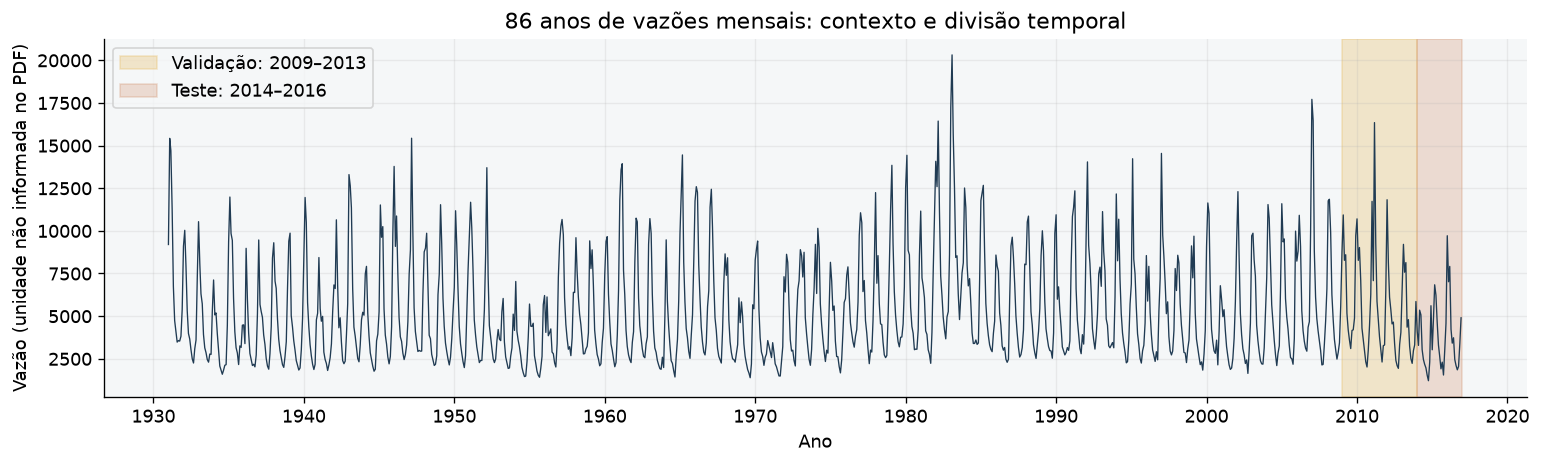

In [3]:
treino_inicial = serie.loc[:"2008-12-01"]
treino_teste = serie.loc[:"2013-12-01"]
teste = serie.loc["2014-01-01":]
assert (len(treino_inicial), len(treino_teste), len(teste)) == (936, 996, 36)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(serie, color=CORES["observado"], linewidth=0.8)
ax.axvspan(mdates.date2num(date(2009, 1, 1)), mdates.date2num(date(2014, 1, 1)), color="#E7B95D", alpha=0.3, label="Validação: 2009–2013")
ax.axvspan(mdates.date2num(date(2014, 1, 1)), mdates.date2num(date(2017, 1, 1)), color="#C46A39", alpha=0.2, label="Teste: 2014–2016")
ax.set(title="86 anos de vazões mensais: contexto e divisão temporal", ylabel=UNIDADE, xlabel="Ano")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 3. Distribuições e sazonalidade
O boxplot mostra mediana (linha interna), quartis (caixa), dispersão e valores
além dos bigodes (pontos). Um ponto isolado é extremo segundo essa regra gráfica;
isso **não prova erro de medição**. Os boxplots mensais comparam os mesmos meses
de anos diferentes. Os anuais comparam a distribuição dos 12 meses de cada ano.
A média e a mediana mensal abaixo usam apenas 1931–2008, evitando que o teste
determine a nossa interpretação da sazonalidade usada na modelagem.

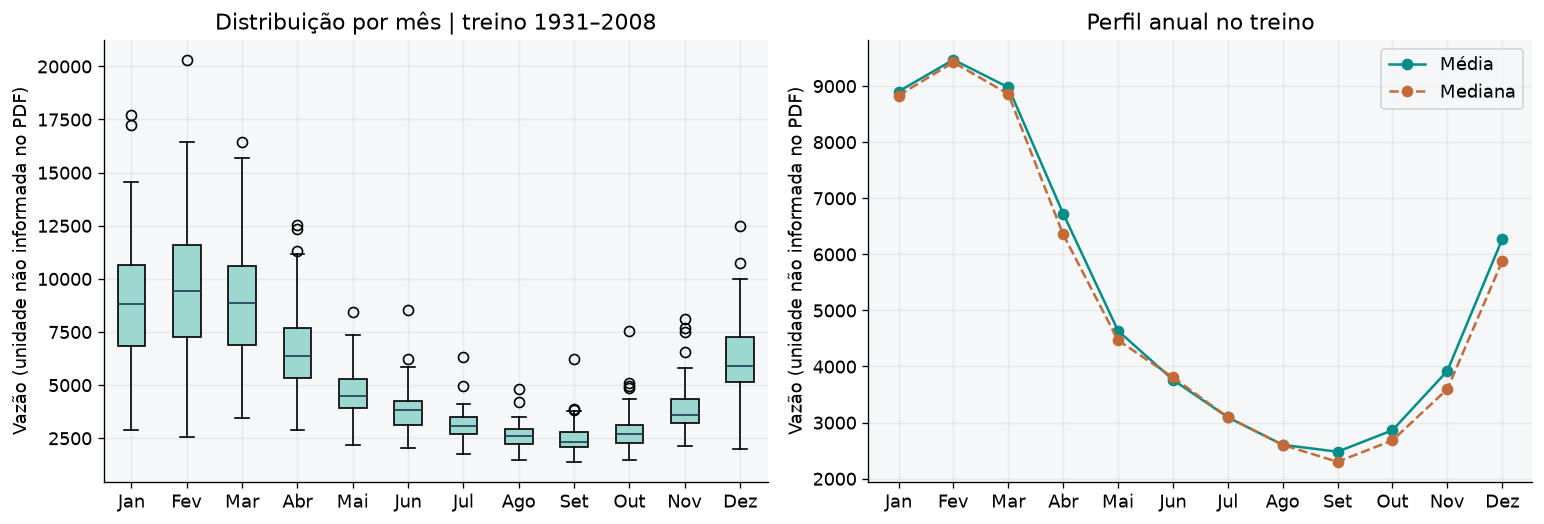

Maior média mensal no treino: Fev; menor: Set.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].boxplot([treino_inicial[treino_inicial.index.month == m] for m in range(1, 13)],
                tick_labels=MESES, patch_artist=True,
                boxprops={"facecolor": "#9CD7D0"}, medianprops={"color": "#203B53"})
axes[0].set(title="Distribuição por mês | treino 1931–2008", ylabel=UNIDADE)
por_mes = treino_inicial.groupby(treino_inicial.index.month).agg(["mean", "median"])
axes[1].plot(range(1, 13), por_mes["mean"], "o-", color=CORES["SARIMA"], label="Média")
axes[1].plot(range(1, 13), por_mes["median"], "o--", color=CORES["ARIMA"], label="Mediana")
axes[1].set(xticks=range(1, 13), xticklabels=MESES, title="Perfil anual no treino", ylabel=UNIDADE)
axes[1].legend()
plt.tight_layout()
plt.show()
print(f"Maior média mensal no treino: {MESES[por_mes['mean'].idxmax()-1]}; "
      f"menor: {MESES[por_mes['mean'].idxmin()-1]}.")

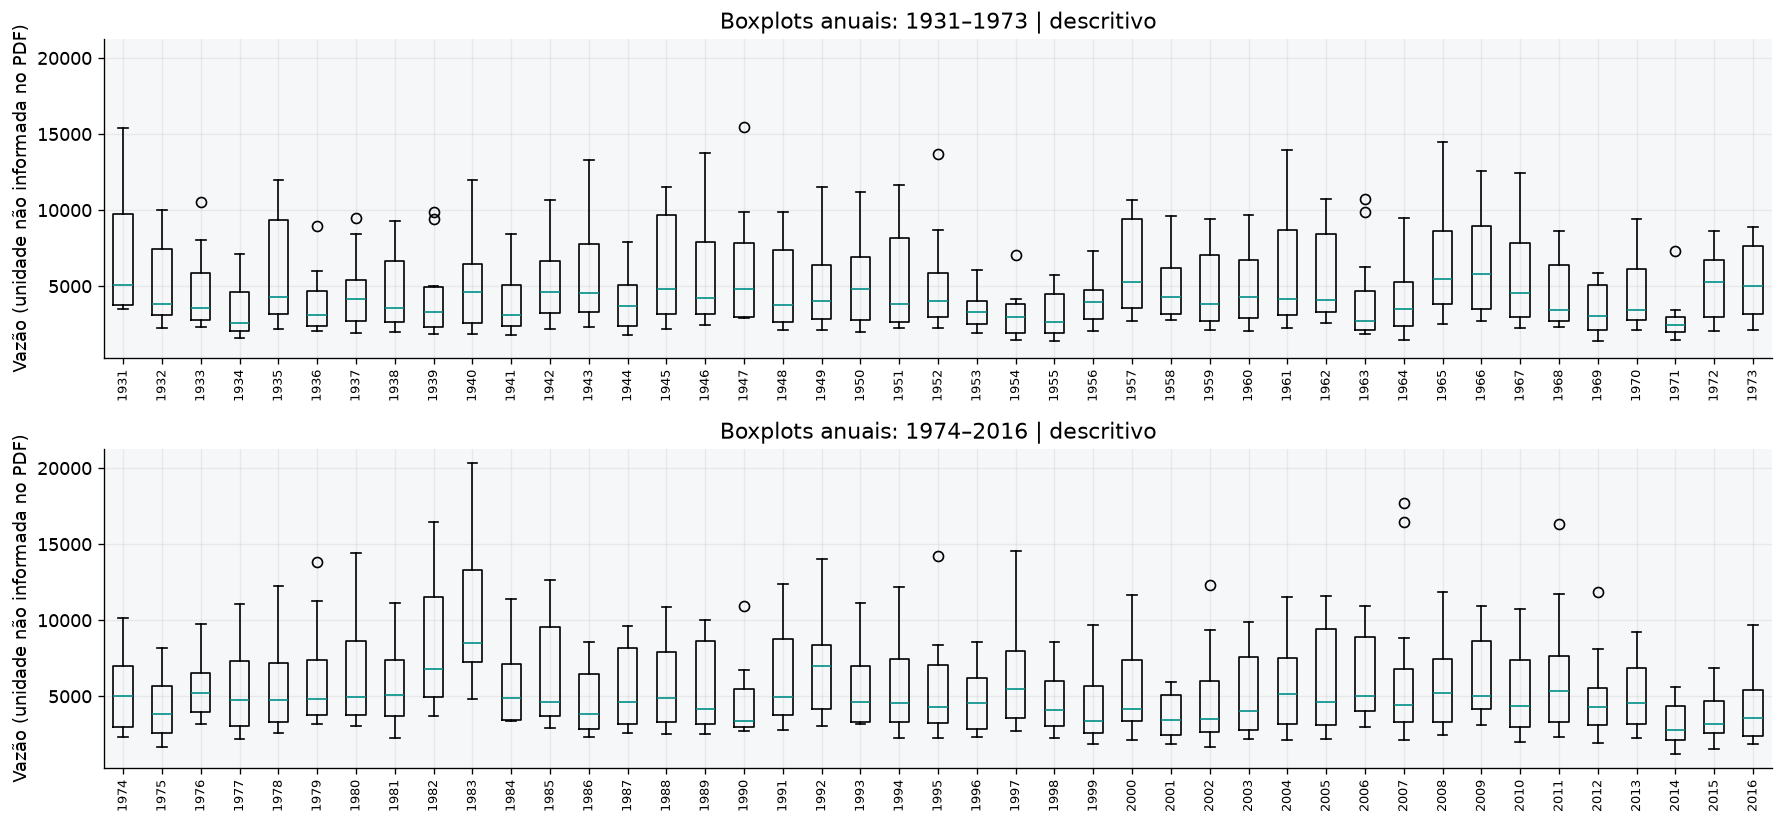

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharey=True)
for ax, anos in zip(axes, [range(1931, 1974), range(1974, 2017)]):
    ax.boxplot([serie[serie.index.year == ano] for ano in anos], tick_labels=list(anos),
               showfliers=True, medianprops={"color": CORES["SARIMA"]})
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.set(ylabel=UNIDADE, title=f"Boxplots anuais: {anos.start}–{anos.stop-1} | descritivo")
plt.tight_layout()
plt.show()

## 4. Logaritmo, médias móveis e decomposição
Usamos `z = log(y)` porque todas as vazões são positivas e o logaritmo comprime
picos elevados. Uma diferença de log representa aproximadamente uma variação
relativa, e a transformação inversa garante previsões positivas.
Isso não garante variância constante nem normalidade: verificaremos os resíduos.

A média móvel de 12 meses suaviza o ciclo anual; o desvio móvel descreve mudanças
na dispersão local. Não são previsões nem dados substitutos para o ajuste.
A decomposição clássica é exploratória: aditiva, `y=T+S+R`, e multiplicativa,
`y=T×S×R`. O período correto para o ciclo anual mensal é **12**. Usar metade
da extensão da série, como em um exemplo, não representa esse ciclo.
A tendência centrada usa vizinhos dos dois lados dentro do treino; por isso
não a usamos como uma variável preditora disponível em tempo real.

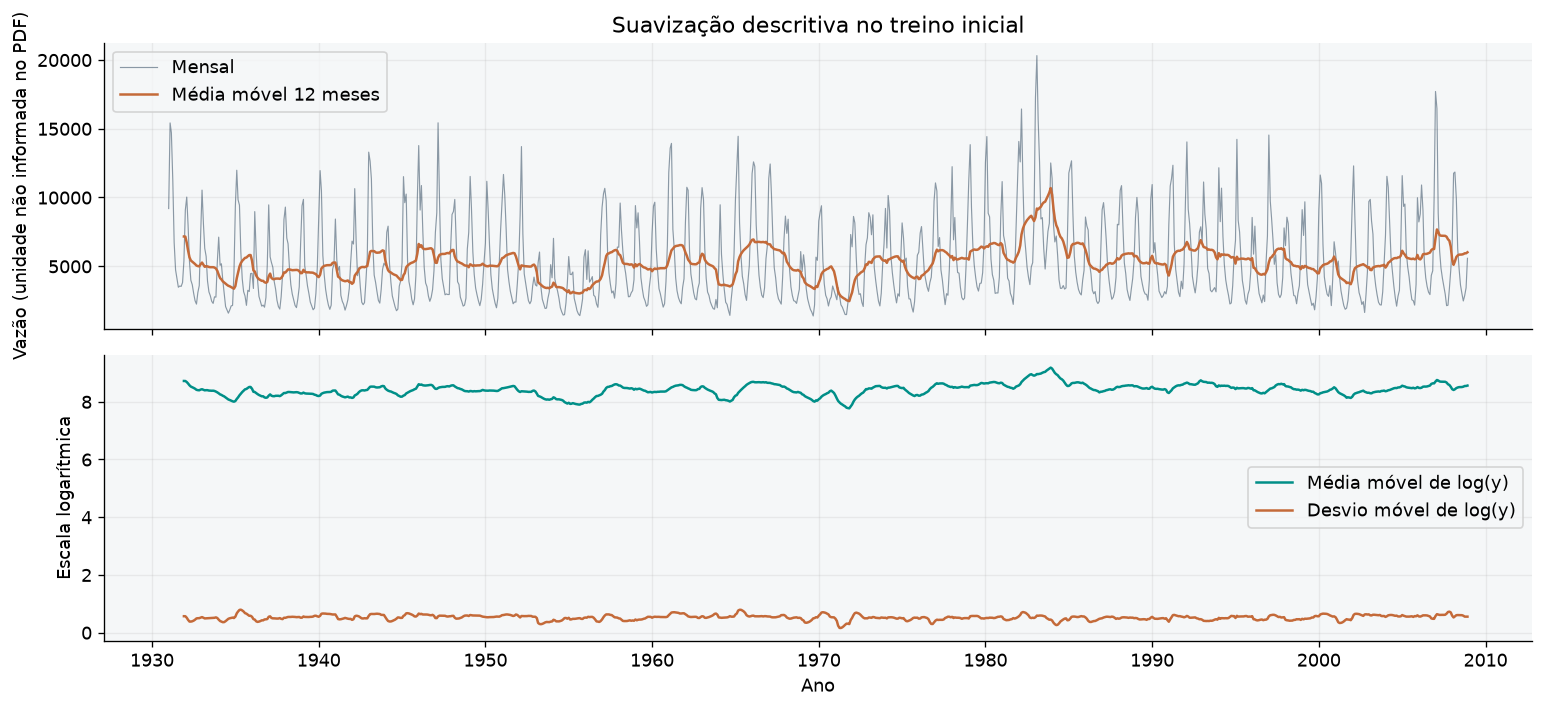

In [6]:
log_treino = np.log(treino_inicial)
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(treino_inicial, color=CORES["observado"], alpha=0.5, linewidth=0.7, label="Mensal")
axes[0].plot(treino_inicial.rolling(12).mean(), color=CORES["ARIMA"], label="Média móvel 12 meses")
axes[0].set(ylabel=UNIDADE, title="Suavização descritiva no treino inicial")
axes[0].legend()
axes[1].plot(log_treino.rolling(12).mean(), color=CORES["SARIMA"], label="Média móvel de log(y)")
axes[1].plot(log_treino.rolling(12).std(), color=CORES["ARIMA"], label="Desvio móvel de log(y)")
axes[1].set(ylabel="Escala logarítmica", xlabel="Ano")
axes[1].legend()
plt.tight_layout()
plt.show()

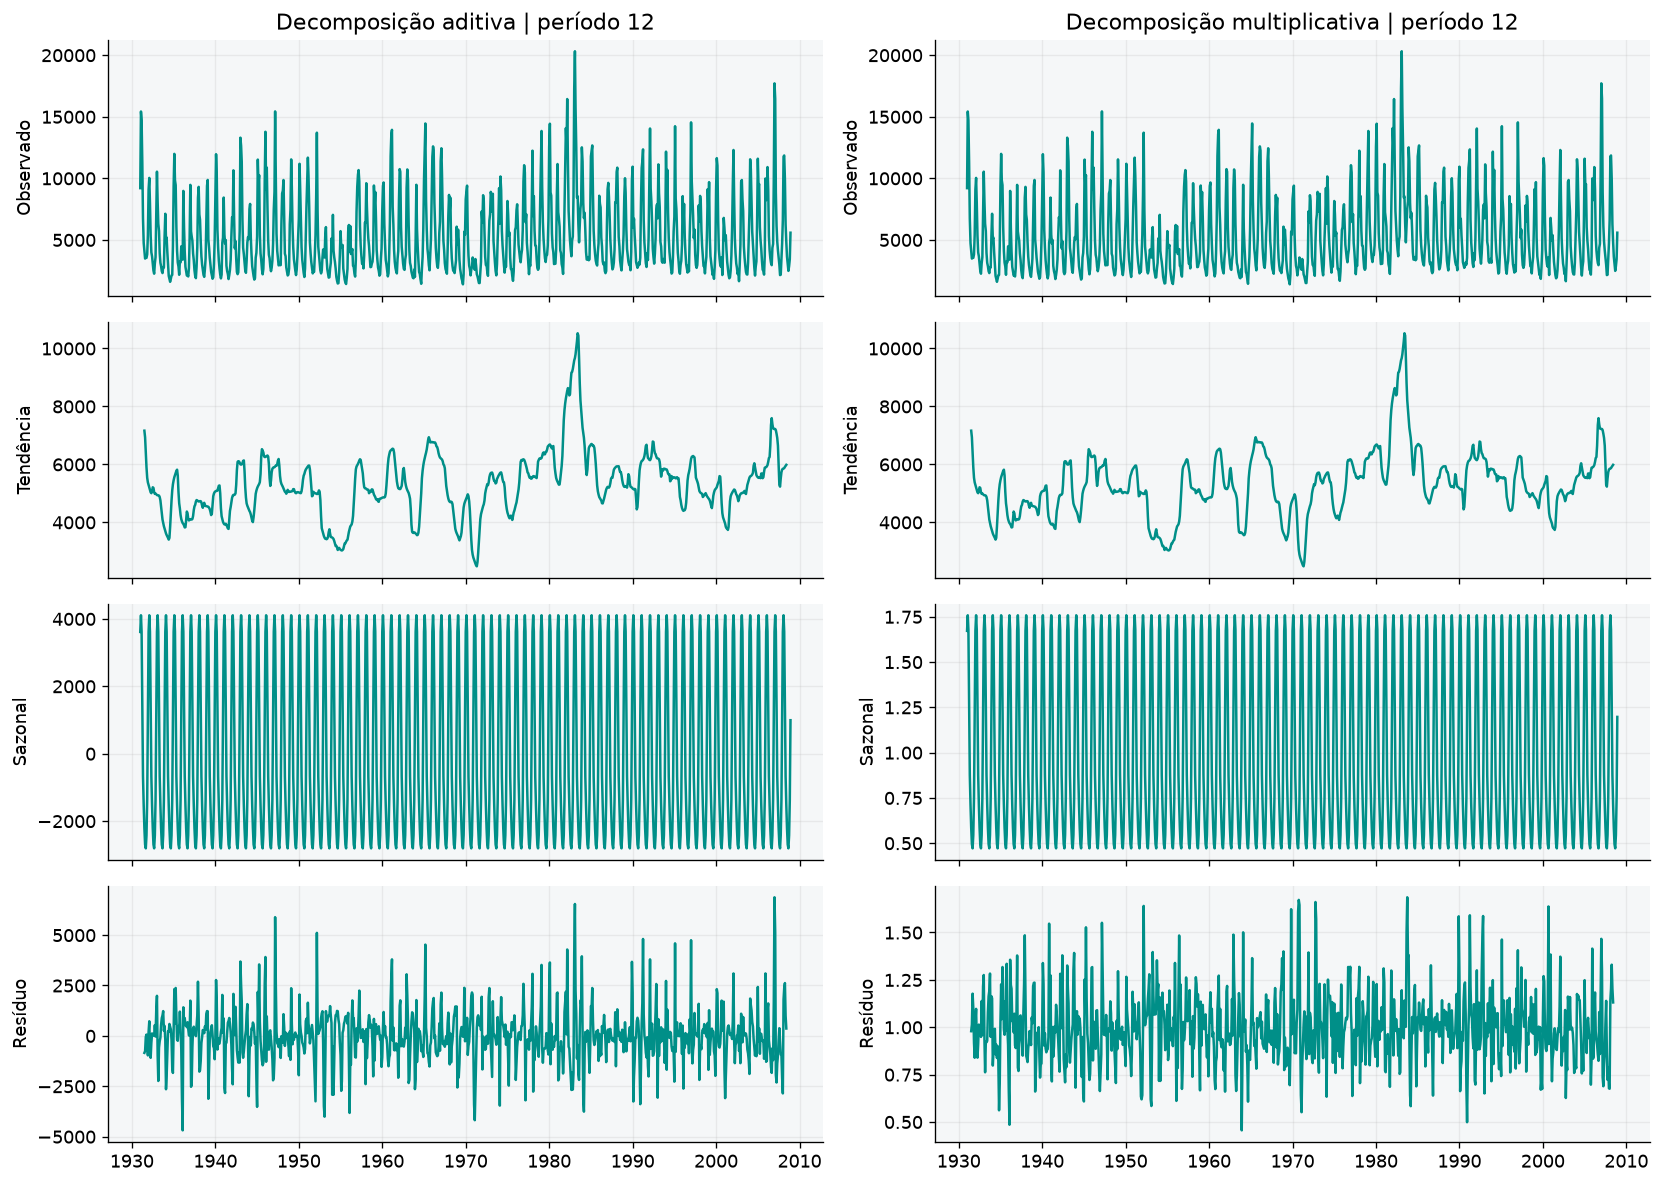

In [7]:
decomposicoes = {
    nome: seasonal_decompose(treino_inicial, model=nome, period=12)
    for nome in ("additive", "multiplicative")
}
fig, axes = plt.subplots(4, 2, figsize=(14, 10), sharex=True)
for coluna, (nome, decomposicao) in enumerate(decomposicoes.items()):
    for linha, atributo in enumerate(["observed", "trend", "seasonal", "resid"]):
        axes[linha, coluna].plot(getattr(decomposicao, atributo), color=CORES["SARIMA"])
        axes[linha, coluna].set_ylabel(["Observado", "Tendência", "Sazonal", "Resíduo"][linha])
    axes[0, coluna].set_title(f"Decomposição {'aditiva' if nome == 'additive' else 'multiplicativa'} | período 12")
plt.tight_layout()
plt.show()

## 5. Estacionariedade e diferenças
Uma série fracamente estacionária tem média e variância constantes e dependência
temporal que depende da distância entre observações, não da data. Uma série
sazonal pode ter dependência anual forte mesmo quando o ADF rejeita raiz unitária.

**ADF:** hipótese nula = existe raiz unitária; p < 0,05 fornece evidência contra
essa hipótese. **KPSS:** hipótese nula = estacionariedade em nível; p < 0,05
fornece evidência contra ela. Ambos são calculados com constante, sem tendência
determinística. Os testes têm limitações diante de quebras e mudanças históricas.
`testar_estacionariedade()` aplica os dois testes a quatro transformações,
escolhe defasagens do ADF por AIC e do KPSS automaticamente, e conserva avisos.
O p-valor do KPSS pode atingir os limites da tabela; não leia esses limites como
probabilidades exatas. Discordância entre testes exige inspeção e validação.

`diff(1)` calcula `log(y_t)−log(y_{t−1})`; `diff(12)` compara o mesmo mês
com o ano anterior. A ordem **d** é a diferença comum, **D** a sazonal.
**q** é o número de termos de médias móveis dos erros, não uma diferenciação.

,serie,n,ADF,ADF_p,ADF_lags,KPSS,KPSS_p
0,original,936,-4.518685,0.000182,21,0.539535,0.032762
1,log,936,-4.081858,0.001038,21,0.773351,0.010000
2,diff_log_1,935,-12.200593,0.000000,21,0.033409,0.100000
3,diff_log_12,924,-8.198579,0.000000,21,0.034581,0.100000


log: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

diff_log_1: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

diff_log_12: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.



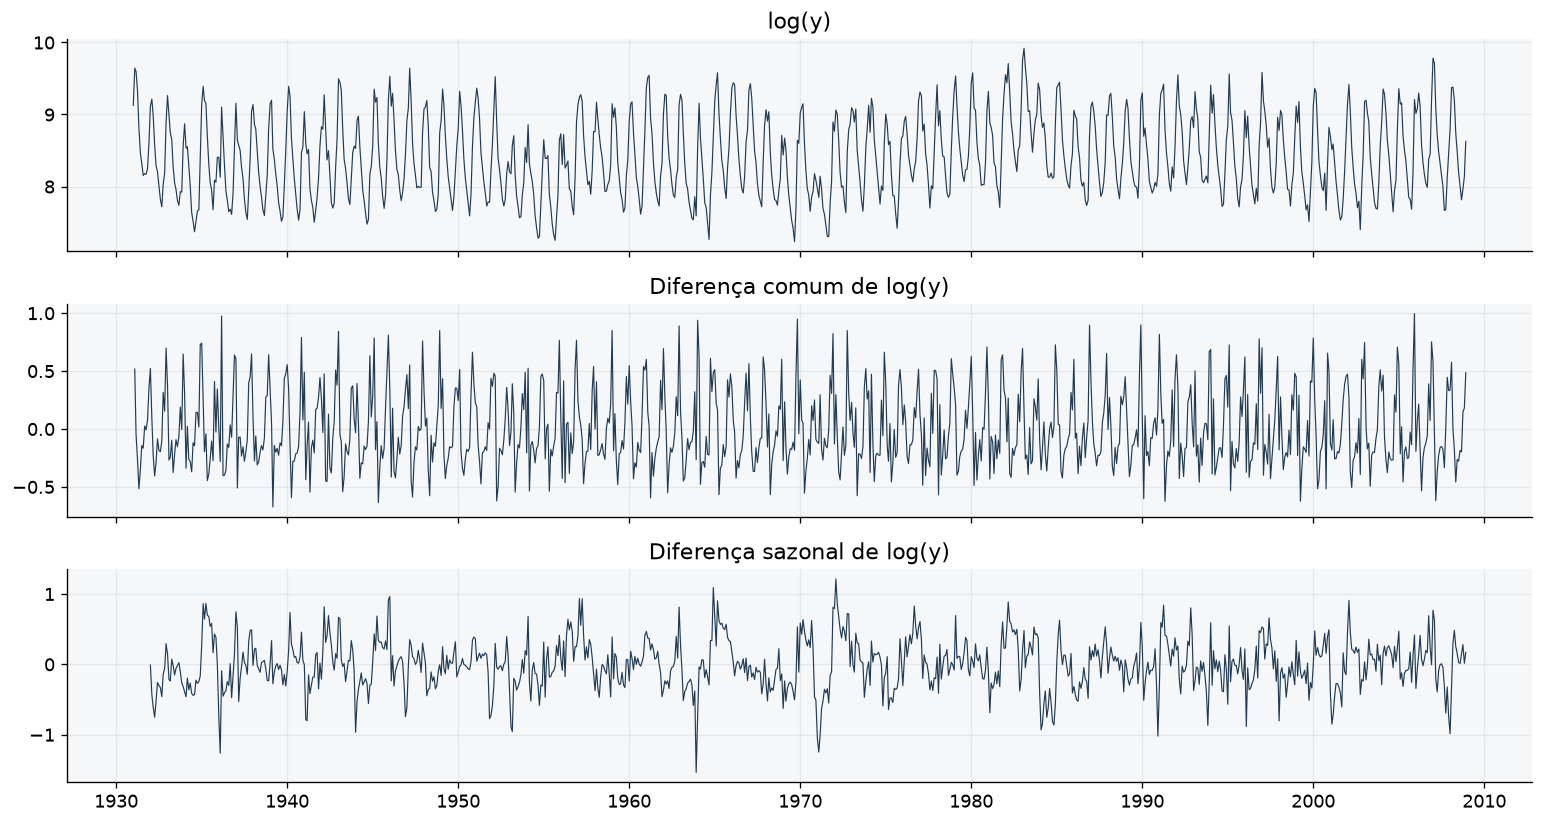

In [8]:
estacionariedade = testar_estacionariedade(treino_inicial)
display(estacionariedade.drop(columns="avisos").round(6))
for _, linha in estacionariedade.iterrows():
    if linha.avisos:
        print(f"{linha.serie}: {linha.avisos}")
transformacoes = {"log(y)": log_treino, "Diferença comum de log(y)": log_treino.diff().dropna(),
                  "Diferença sazonal de log(y)": log_treino.diff(12).dropna()}
fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
for ax, (nome, valores) in zip(axes, transformacoes.items()):
    ax.plot(valores, color=CORES["observado"], linewidth=0.7)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

## 6. ACF e PACF: pistas, não uma regra automática
A ACF mede correlação com valores anteriores; a PACF retira a contribuição das
defasagens intermediárias. Picos em 12, 24 e 36 sugerem dependência anual.
AR(p) pode produzir corte na PACF; MA(q), na ACF. Dados reais raramente exibem
um corte perfeito. As faixas de 95% são aproximadas e ponto a ponto; investigar
muitas defasagens pode produzir picos ao acaso. Fixamos `method='ywm'` na PACF.
O notebook mostra 36 meses para tornar três ciclos anuais visíveis.

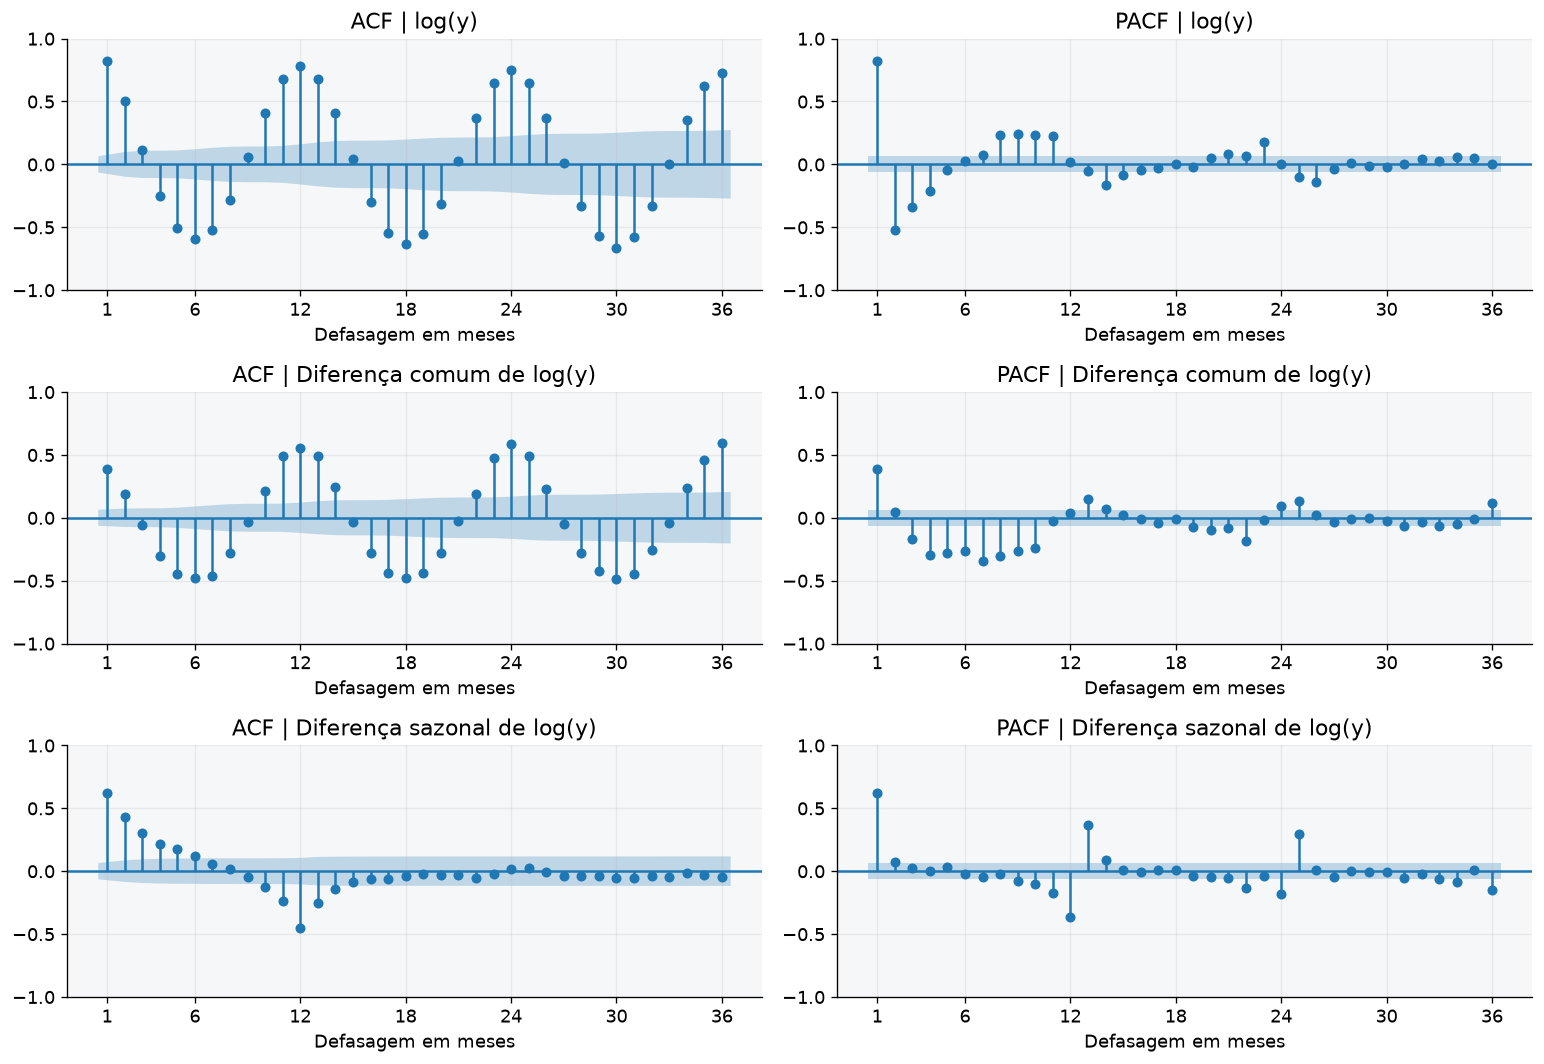

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9))
for linha, (nome, valores) in enumerate(transformacoes.items()):
    plot_acf(valores, lags=36, zero=False, ax=axes[linha, 0], title=f"ACF | {nome}")
    plot_pacf(valores, lags=36, zero=False, method="ywm", ax=axes[linha, 1], title=f"PACF | {nome}")
    for ax in axes[linha]:
        ax.set_xticks([1, 6, 12, 18, 24, 30, 36])
        ax.set_xlabel("Defasagem em meses")
plt.tight_layout()
plt.show()

## 7. O que significam ARIMA e SARIMA?
**ARIMA(p,d,q)** usa a persistência dos valores anteriores (AR), diferenças (I)
e erros passados (MA). **SARIMA(p,d,q)(P,D,Q)[12]** acrescenta relações sazonais,
como a dependência com 12 meses de distância. Ambos são ajustados sobre `log(y)`.
A classe `SARIMAX` de statsmodels implementa também o ARIMA quando a parte
sazonal é zero. Não usamos variáveis exógenas neste projeto.

`especificacoes()` gera uma grade deliberadamente pequena: ARIMA com p e q em
{0,1,2}, d em {0,1}; SARIMA com p,q,P,D,Q em {0,1}, d=0 e período 12,
excluindo P=D=Q=0. Portanto não alegamos encontrar o melhor modelo possível
entre todas as ordens. Para séries diferenciadas usamos `trend='n'` (sem deriva);
para d=D=0 usamos `trend='c'` (constante no modelo). A constante do SARIMAX
não é diretamente a média incondicional da série quando existem termos AR.

`ajustar()` estima os parâmetros por máxima verossimilhança, limita o otimizador
a 250 iterações e impõe estacionariedade/invertibilidade à parte ARMA, após as
diferenças. Ele rejeita ajustes sem convergência ou com AIC não finito e registra
os avisos, em vez de escondê-los.
Antes do ajuste, subtrai a média de log(y) calculada apenas no treino daquela
origem. Essa centralização melhora a escala numérica da otimização, especialmente
quando um coeficiente sazonal fica próximo de 1. Guardamos `centro_log` no ajuste
e o somamos de volta à média e aos limites logarítmicos antes da exponenciação.
O intercepto da tabela pertence à série logarítmica centralizada.

In [10]:
grade = pd.DataFrame(especificacoes())
display(grade.groupby("familia")["id"].count().to_frame("Candidatos"))
display(grade.head())

,Candidatos
familia,
ARIMA,18
SARIMA,28


,familia,order,seasonal_order,trend,id
0,ARIMA,"(0, 0, 0)","(0, 0, 0, 0)",c,ARIMA_00
1,ARIMA,"(0, 0, 1)","(0, 0, 0, 0)",c,ARIMA_01
2,ARIMA,"(0, 0, 2)","(0, 0, 0, 0)",c,ARIMA_02
3,ARIMA,"(0, 1, 0)","(0, 0, 0, 0)",n,ARIMA_03
4,ARIMA,"(0, 1, 1)","(0, 0, 0, 0)",n,ARIMA_04


## 8. Escolha antes de olhar o teste
AIC = `−2 log L + 2k`: equilibra ajuste e complexidade. Só comparamos AIC de
candidatos da mesma família e mesmos d,D, na mesma série e janela inicial.
`selecionar()` leva os dois menores AIC de cada grupo para a validação. Em cada
uma das cinco origens, ele reajusta o candidato usando somente o passado e
prevê 12 meses. Um candidato precisa convergir nas cinco origens.
O menor **RMSE médio entre os cinco anos** escolhe um modelo de cada família.
O AIC não substitui erro fora da amostra; o teste 2014–2016 fica reservado.

No modo rápido, lemos as especificações registradas em `output/resumo.json` e
o ranking. Esses arquivos documentam a busca já executada. A seguir, os modelos
escolhidos serão reajustados de verdade; os resultados não serão apenas imagens.
Se faltarem os arquivos, execute `.venv/bin/python scripts/analisar.py` na raiz,
ou ative a busca completa nesta célula.

In [11]:
if REFAZER_BUSCA:
    selecionados, ranking = selecionar(serie)
else:
    if not (ROOT / "output/resumo.json").is_file():
        raise FileNotFoundError("Execute .venv/bin/python scripts/analisar.py ou use REFAZER_BUSCA=True.")
    resumo = json.loads((ROOT / "output/resumo.json").read_text())
    selecionados = resumo["selecionados"]
    ranking = pd.read_csv(TABELAS / "ranking_validacao.csv")
display(ranking.round(3))
display(pd.DataFrame(selecionados).T)
for familia, spec in selecionados.items():
    melhor_validacao = ranking.loc[ranking.familia == familia].sort_values("RMSE").iloc[0]
    assert spec["id"] == melhor_validacao.id
    registrado = next(item for item in especificacoes() if item["id"] == spec["id"])
    assert tuple(spec["order"]) == registrado["order"]
    assert tuple(spec["seasonal_order"]) == registrado["seasonal_order"]
busca = pd.read_csv(TABELAS / "busca_modelos.csv")
print(f"Convergiram {busca.convergiu.sum()} de {len(busca)} candidatos na busca inicial.")
if (~busca.convergiu).any():
    display(busca.loc[~busca.convergiu, ["id", "avisos"]])

,familia,id,RMSE,MAE,MAPE,MASE
0,SARIMA,SARIMA_36,1566.833,1114.940,18.761,0.727
1,SARIMA,SARIMA_45,1603.630,1141.574,19.176,0.744
2,SARIMA,SARIMA_41,1606.315,1144.997,19.161,0.746
3,ARIMA,ARIMA_14,1699.748,1279.370,25.365,0.834
4,ARIMA,ARIMA_13,1810.677,1380.814,28.913,0.900
5,ARIMA,ARIMA_17,2735.487,2296.749,45.675,1.497
6,ARIMA,ARIMA_11,20854.242,17407.810,490.443,11.347


,familia,order,seasonal_order,trend,id
ARIMA,ARIMA,"[2, 0, 2]","[0, 0, 0, 0]",c,ARIMA_14
SARIMA,SARIMA,"[1, 0, 0]","[1, 0, 1, 12]",c,SARIMA_36


Convergiram 46 de 46 candidatos na busca inicial.


## 9. Ajustar novamente e interpretar os parâmetros
`ajustar(treino_teste, spec)` usa somente dados até dezembro de 2013. A tabela
mostra coeficiente, erro padrão, p-valor e intervalo de 95% **do parâmetro**.
`ar.L1` representa dependência AR na defasagem 1; `ma.L1` representa o efeito
de uma inovação passada; `ar.S.L12` e `ma.S.L12` são os equivalentes sazonais.
`sigma2` estima a variância das inovações na escala logarítmica.

Os p-valores pressupõem o modelo e suas hipóteses; significância individual não
prova capacidade preditiva. Tampouco o intervalo de um coeficiente é uma faixa
para vazões futuras. Essa distinção corrige o uso de `fitted.conf_int()` no exemplo.

In [12]:
ajustes = {}
for familia, spec in selecionados.items():
    ajuste, avisos = ajustar(treino_teste, spec)
    ajustes[familia] = ajuste
    parametros = pd.DataFrame({"coeficiente": ajuste.params, "erro_padrao": ajuste.bse,
                               "p_valor": ajuste.pvalues})
    parametros[["inferior_95", "superior_95"]] = ajuste.conf_int().to_numpy()
    display(Markdown(f"### {familia} {tuple(spec['order'])} × {tuple(spec['seasonal_order'])}"))
    display(parametros.round(6))
    print("Convergência:", ajuste.mle_retvals["converged"], "| Avisos:", avisos or "nenhum")

### ARIMA (2, 0, 2) × (0, 0, 0, 0)

,coeficiente,erro_padrao,p_valor,inferior_95,superior_95
intercept,-0.000098,0.004573,0.982861,-0.009060,0.008864
ar.L1,1.635367,0.022976,0.000000,1.590335,1.680399
ar.L2,-0.878451,0.020724,0.000000,-0.919070,-0.837832
ma.L1,-0.725791,0.037314,0.000000,-0.798925,-0.652656
ma.L2,0.236267,0.035887,0.000000,0.165930,0.306604
sigma2,0.060386,0.002534,0.000000,0.055419,0.065352


Convergência: True | Avisos: nenhum


### SARIMA (1, 0, 0) × (1, 0, 1, 12)

,coeficiente,erro_padrao,p_valor,inferior_95,superior_95
intercept,-0.000003,0.000021,0.894873,-0.000045,0.000039
ar.L1,0.720417,0.020129,0.000000,0.680964,0.759869
ar.S.L12,0.999661,0.000392,0.000000,0.998893,1.000429
ma.S.L12,-0.970896,0.015345,0.000000,-1.000971,-0.940821
sigma2,0.039737,0.001443,0.000000,0.036908,0.042565


Convergência: True | Avisos: nenhum


## 10. Previsão e intervalo de 95% na escala original
`get_forecast(steps=h)` produz a distribuição preditiva para h meses.
O método `prever()` pede `conf_int(alpha=0.05)` **ao objeto de previsão**.
Se o log da vazão futura for aproximadamente normal, com média μ e variância v:

- mediana na escala original = `exp(μ)`;
- média na escala original = `exp(μ + v/2)`;
- limites = exponencial dos limites de 95% na escala logarítmica.

Usamos a média para calcular erros quadráticos. Exponenciar apenas μ daria a
mediana, geralmente menor. A transformação preserva a cobertura dos quantis,
mas produz faixas assimétricas, o que faz sentido em uma variável positiva.
São **intervalos de previsão pontuais de 95%**, não intervalos de confiança
da média nem garantia de conter 95% de uma trajetória inteira. São condicionais
ao modelo e aos parâmetros estimados e não incorporam toda a incerteza da seleção,
quebras estruturais ou novas condições hidrológicas.

In [13]:
previsoes = {familia: prever(ajuste, len(teste)) for familia, ajuste in ajustes.items()}
for familia, previsao in previsoes.items():
    assert previsao.index.equals(teste.index)
    assert np.isfinite(previsao.to_numpy()).all()
    assert (previsao.inferior_95 > 0).all()
    assert (previsao.inferior_95 < previsao.superior_95).all()
    assert (previsao.media >= previsao.mediana).all()
display(previsoes["SARIMA"].head().round(2))

,media,mediana,inferior_95,superior_95
2014-01-01,8681.19,8510.34,5757.47,12579.46
2014-02-01,9129.09,8857.58,5472.00,14337.85
2014-03-01,8846.47,8537.53,5062.61,14397.61
2014-04-01,6862.79,6604.75,3838.79,11363.66
2014-05-01,4807.12,4619.71,2658.03,8029.14


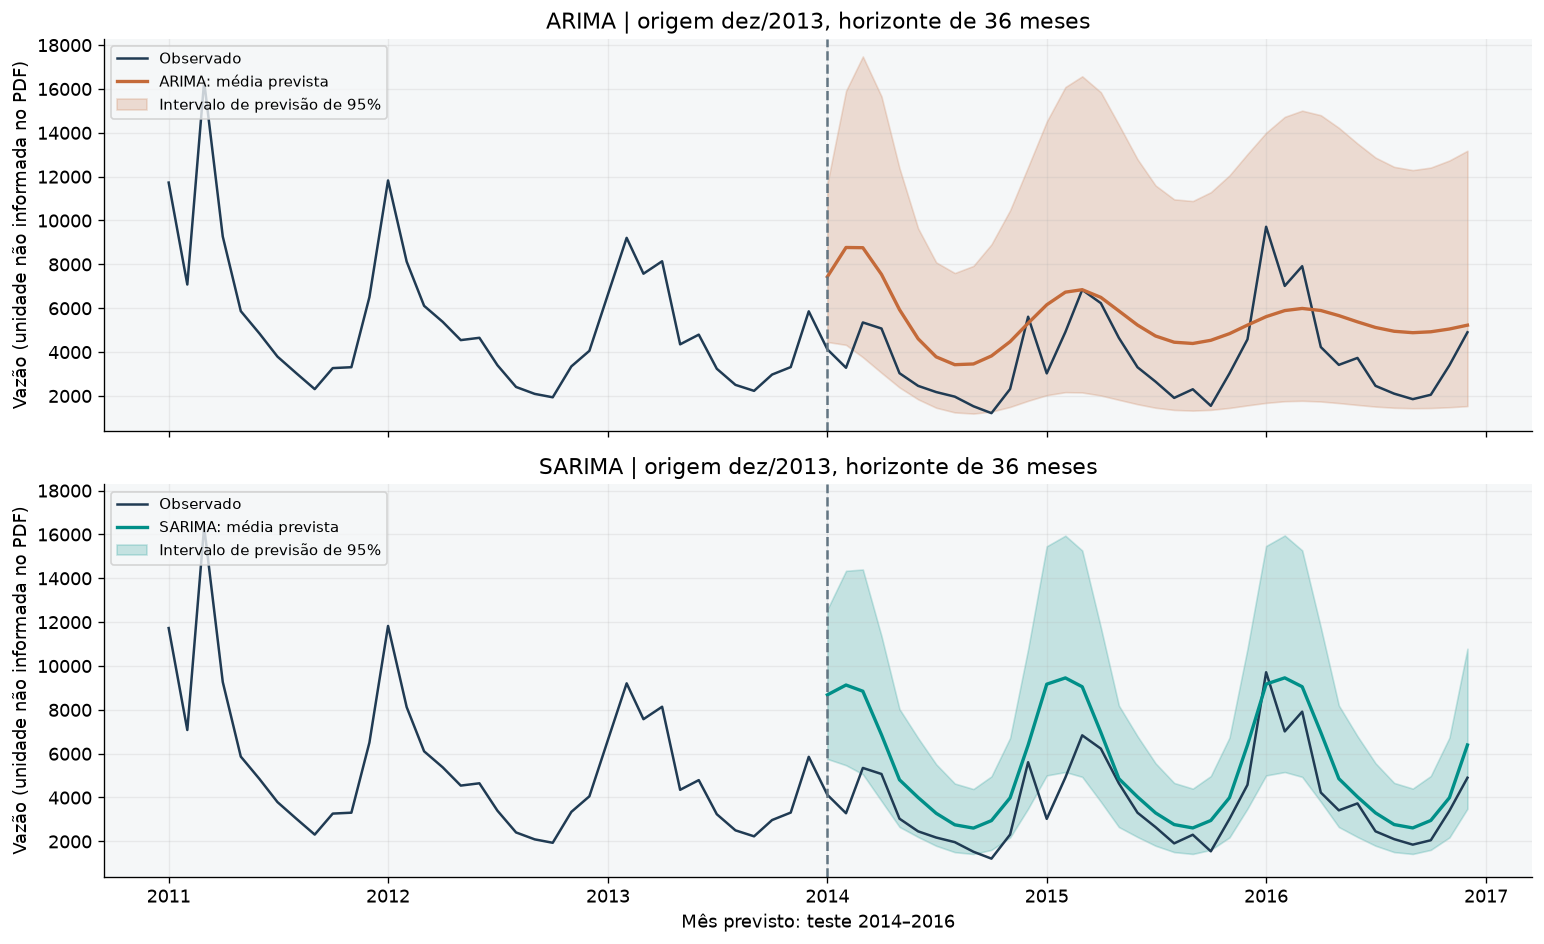

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, sharey=True)
for ax, (familia, previsao) in zip(axes, previsoes.items()):
    ax.plot(serie.loc["2011":], color=CORES["observado"], label="Observado", linewidth=1.5)
    ax.plot(previsao.media, color=CORES[familia], linewidth=2, label=f"{familia}: média prevista")
    ax.fill_between(previsao.index, previsao.inferior_95, previsao.superior_95,
                    color=CORES[familia], alpha=0.2, label="Intervalo de previsão de 95%")
    ax.axvline(pd.Timestamp("2014-01-01"), color="#627582", linestyle="--")
    ax.set(title=f"{familia} | origem dez/2013, horizonte de 36 meses", ylabel=UNIDADE)
    ax.legend(fontsize=9, loc="upper left")
axes[-1].set_xlabel("Mês previsto: teste 2014–2016")
plt.tight_layout()
plt.show()

## 11. Comparar com referências simples e medir os erros
O **ingênuo sazonal** repete os 12 meses de 2013 para cada ano do teste. A
**média por mês** usa a média histórica de cada mês, calculada até 2013.
Assim ambos conhecem exatamente o mesmo passado dos modelos. São referências
pontuais; não inventamos intervalos para elas.

`metricas()` transforma os valores em vetores alinhados e calcula:
**RMSE** = raiz do erro quadrático médio (penaliza picos);
**MAE** = erro absoluto médio (unidade da vazão);
**MAPE** = erro absoluto percentual médio (pode exagerar erros em vazões baixas);
**MASE** = MAE dividido pelo erro sazonal de um passo de 12 meses no treino.
MASE < 1 melhora essa escala histórica, não necessariamente o ingênuo sazonal
observado neste teste. Para comparar com ele, olhe as métricas das duas linhas.
A cobertura é a fração dos 36 valores dentro do intervalo; a largura média
mede o custo dessa cobertura. Faixas largas podem cobrir muito sem ser úteis.

,RMSE,MAE,MAPE,MASE,cobertura_95,largura_media_95
modelo,,,,,,
ARIMA,2390.47,2122.36,76.83,1.39,91.67,10908.00
SARIMA,2233.74,1684.14,52.31,1.10,83.33,6026.34
Ingênuo sazonal,2012.57,1508.67,45.47,0.98,NaN,NaN
Média por mês,2214.93,1594.40,48.75,1.04,NaN,NaN


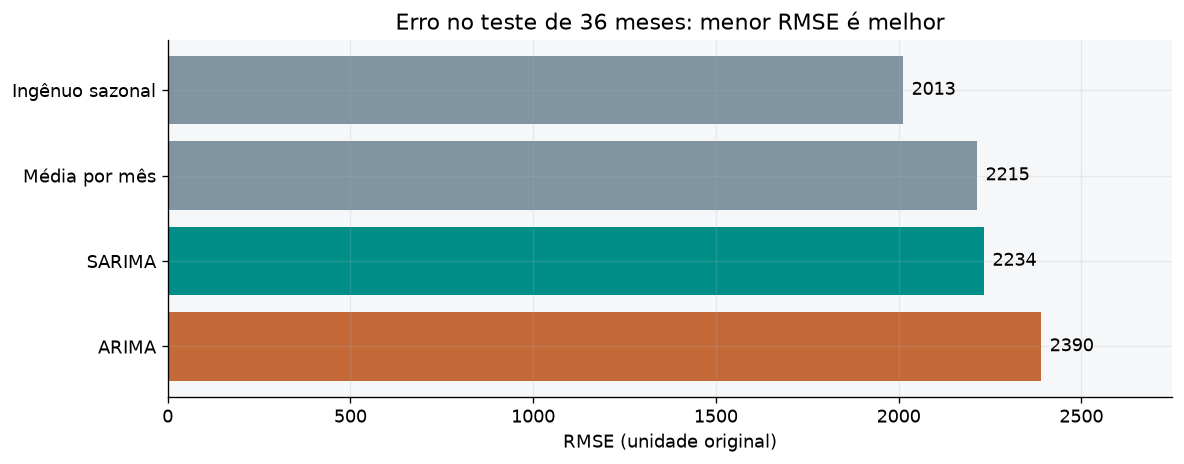

Menor RMSE no teste: Ingênuo sazonal
Média até 2013: 5325.82 | Média em 2014–2016: 3772.94


In [15]:
baselines = {
    "Ingênuo sazonal": pd.Series(np.tile(treino_teste.iloc[-12:].to_numpy(), 3), index=teste.index),
    "Média por mês": pd.Series(treino_teste.groupby(treino_teste.index.month).mean()
                              .reindex(teste.index.month).to_numpy(), index=teste.index),
}
linhas_metricas = []
for familia, prev in previsoes.items():
    linhas_metricas.append({"modelo": familia, **metricas(teste, prev.media, treino_teste),
        "cobertura_95": 100 * teste.between(prev.inferior_95, prev.superior_95).mean(),
        "largura_media_95": (prev.superior_95 - prev.inferior_95).mean()})
for nome, prev in baselines.items():
    linhas_metricas.append({"modelo": nome, **metricas(teste, prev, treino_teste)})
scores = pd.DataFrame(linhas_metricas).set_index("modelo")
display(scores.round(2))
fig, ax = plt.subplots(figsize=(10, 4))
ordenado = scores.RMSE.sort_values()
barras = ax.barh(ordenado.index, ordenado.values, color=[CORES.get(m, "#8094A1") for m in ordenado.index])
ax.bar_label(barras, fmt="%.0f", padding=5)
ax.invert_yaxis()
ax.set(title="Erro no teste de 36 meses: menor RMSE é melhor", xlabel="RMSE (unidade original)")
ax.margins(x=0.15)
plt.tight_layout()
plt.show()
print("Menor RMSE no teste:", scores.RMSE.idxmin())
print("Média até 2013:", round(treino_teste.mean(), 2), "| Média em 2014–2016:", round(teste.mean(), 2))

## 12. Os resíduos guardam informação que o modelo deixou escapar?
Usamos inovações de um passo padronizadas pelo seu desvio previsto no filtro.
Descartamos os primeiros `max(24, loglikelihood_burn)` meses para reduzir o efeito
da inicialização. Idealmente a série oscila em torno de zero, sem padrões e com
dispersão estável. O Q–Q plot compara seus quantis com uma distribuição normal.

**Ljung–Box** testa ausência de autocorrelação conjunta até as defasagens 12 e 24;
descontamos p+q+P+Q graus de liberdade. p < 0,05 sugere dependência remanescente.
**Jarque–Bera** testa normalidade; p < 0,05 questiona a hipótese gaussiana usada
nos intervalos. p alto não prova que uma hipótese é verdadeira. Resíduos com
caudas pesadas podem prejudicar a cobertura mesmo quando a previsão pontual é boa.

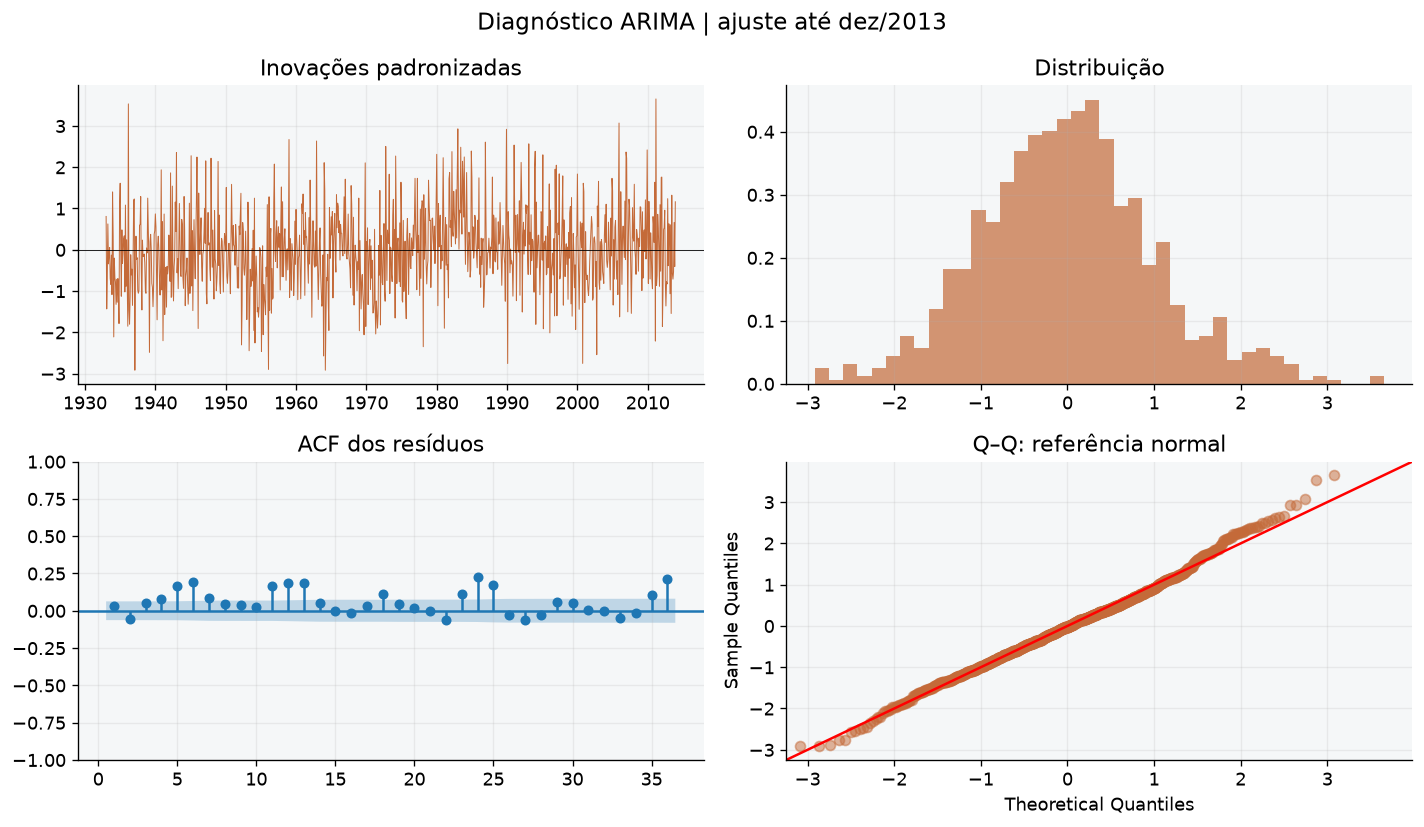

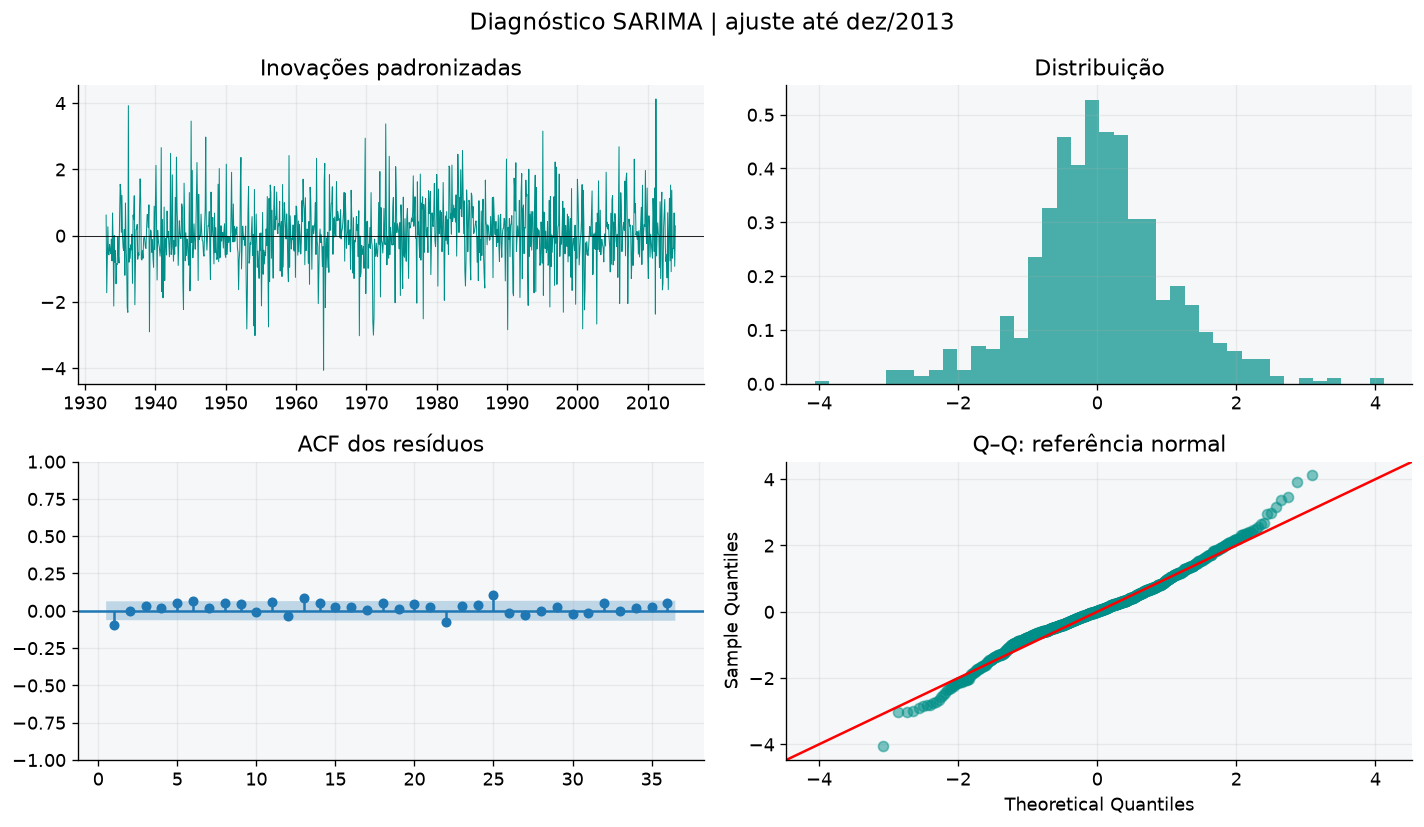

,LB12_p,LB24_p,JB_p,media_residuo,descarte
modelo,,,,,
ARIMA,3.936403e-28,3.952334e-45,9.003117e-04,-0.006357,24
SARIMA,1.214257e-03,2.156564e-04,4.634051e-15,0.044061,24


In [16]:
residuos = {}
diagnosticos = []
for familia, ajuste in ajustes.items():
    spec = selecionados[familia]
    descarte = max(24, ajuste.loglikelihood_burn)
    resid = pd.Series(ajuste.filter_results.standardized_forecasts_error[0, descarte:],
                      index=treino_teste.index[descarte:]).dropna()
    residuos[familia] = resid
    graus = spec["order"][0] + spec["order"][2] + spec["seasonal_order"][0] + spec["seasonal_order"][2]
    lb = acorr_ljungbox(resid, lags=[12, 24], model_df=graus, return_df=True)
    estatistica_jb, p_valor_jb = jarque_bera(resid)
    diagnosticos.append({"modelo": familia, "LB12_p": lb.lb_pvalue.iloc[0],
                         "LB24_p": lb.lb_pvalue.iloc[1], "JB_p": p_valor_jb,
                         "media_residuo": resid.mean(), "descarte": descarte})
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    axes[0, 0].plot(resid, color=CORES[familia], linewidth=0.6)
    axes[0, 0].axhline(0, color="black", linewidth=0.5)
    axes[0, 0].set_title("Inovações padronizadas")
    axes[0, 1].hist(resid, bins=40, density=True, color=CORES[familia], alpha=0.7)
    axes[0, 1].set_title("Distribuição")
    plot_acf(resid, lags=36, zero=False, ax=axes[1, 0], title="ACF dos resíduos")
    qqplot(resid, line="45", ax=axes[1, 1], markerfacecolor=CORES[familia], markeredgecolor=CORES[familia], alpha=0.5)
    axes[1, 1].set_title("Q–Q: referência normal")
    fig.suptitle(f"Diagnóstico {familia} | ajuste até dez/2013", fontsize=14)
    plt.tight_layout()
    plt.show()
diagnosticos = pd.DataFrame(diagnosticos).set_index("modelo")
display(diagnosticos)

## 13. Projetar 2017 usando todo o histórico disponível
Mantemos as ordens escolhidas antes do teste e reestimamos os parâmetros com
1931–2016. A primeira previsão é janeiro de 2017, exatamente um mês após o último
dado. Isso é uma **projeção histórica**, não uma previsão atual de 2026.
O material fornecido não permite calcular erro ou cobertura para 2017.
Os 12 valores, suas médias/medianas e limites ficam na tabela abaixo.

ARIMA: ajuste final convergiu; avisos = nenhum


SARIMA: ajuste final convergiu; avisos = nenhum


ARIMA                                    SARIMA           \
              media  mediana inferior_95 superior_95    media  mediana   
2017-01-01  7007.24  6789.89     4151.29    11105.63  7380.92  7229.14   
2017-02-01  8721.15  8239.47     4255.67    15952.60  8034.52  7787.73   
2017-03-01  9130.07  8438.90     3877.36    18366.88  8167.23  7875.10   
2017-04-01  8098.81  7407.43     3236.49    16953.56  6409.44  6164.01   
2017-05-01  6418.66  5862.28     2544.42    13506.54  4549.00  4369.07   
2017-06-01  4913.12  4483.77     1939.19    10367.32  3800.37  3647.64   
2017-07-01  3915.57  3551.33     1493.64     8443.76  3136.48  3009.44   
2017-08-01  3419.99  3068.37     1231.42     7645.53  2643.98  2536.47   
2017-09-01  3337.50  2963.78     1140.29     7703.35  2502.79  2400.82   
2017-10-01  3604.14  3182.94     1198.01     8456.61  2806.14  2691.70   
2017-11-01  4179.03  3686.71     1381.82     9836.19  3886.86  3728.27   
2017-12-01  4991.84  4403.16     1649.48    11753.94  6239.64  5984.99   

                                    
           inferior_95 superior_95  
2017-01-01     4848.02    10779.75  
2017-02-01     4772.96    12706.73  
2017-03-01     4639.99    13365.82  
2017-04-01     3564.55    10659.16  
2017-05-01     2503.57     7624.61  
2017-06-01     2080.74     6394.51  
2017-07-01     1712.82     5287.63  
2017-08-01     1442.00     4461.64  
2017-09-01     1364.11     4225.42  
2017-10-01     1528.95     4738.69  
2017-11-01     2117.45     6564.49  
2017-12-01     3398.92    10538.68

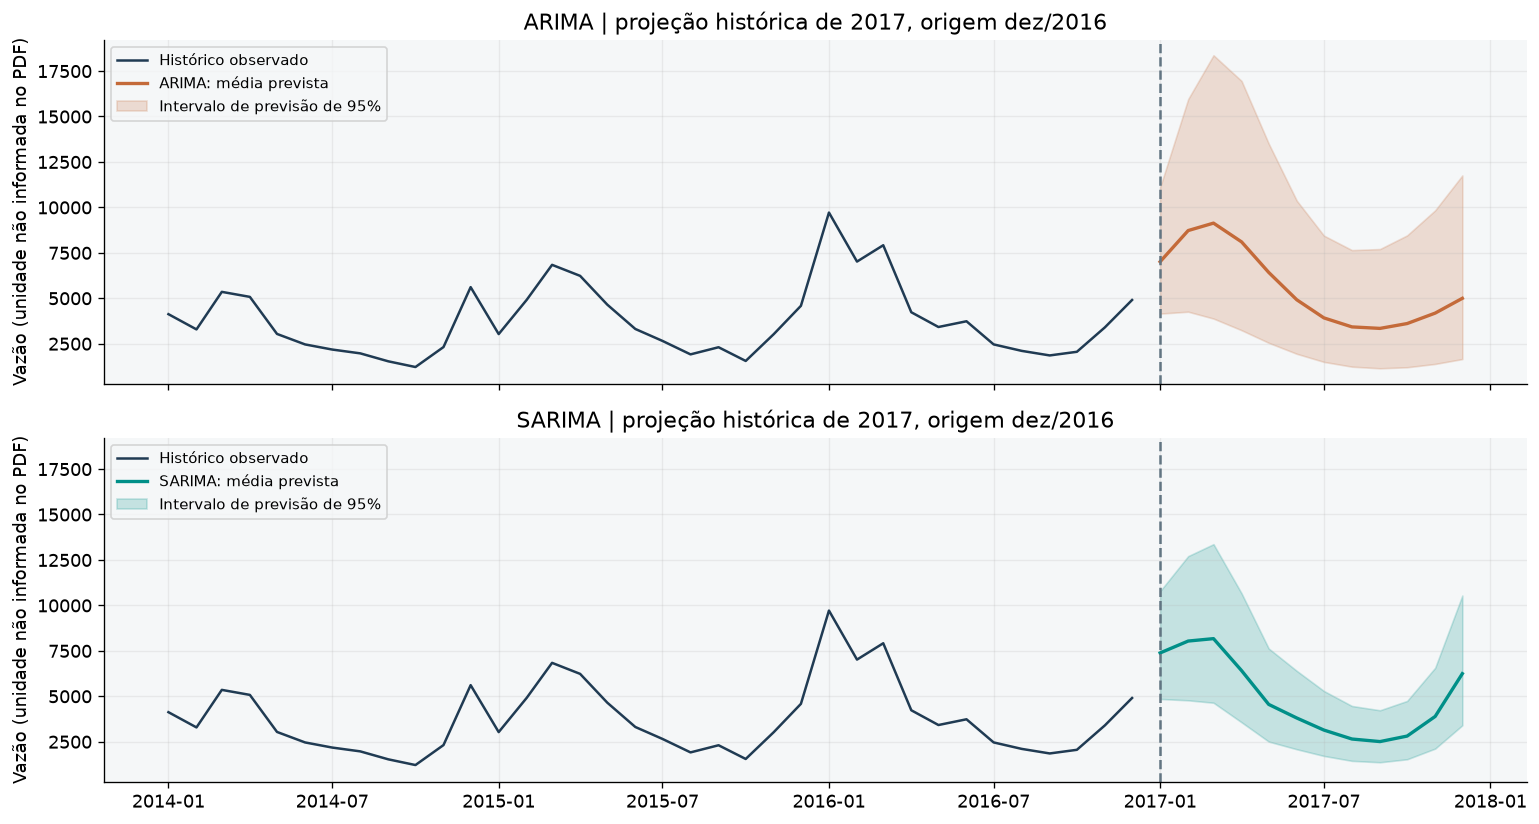

In [17]:
futuro = {}
for familia, spec in selecionados.items():
    ajuste_final, avisos_final = ajustar(serie, spec)
    futuro[familia] = prever(ajuste_final, 12)
    assert futuro[familia].index.equals(pd.date_range("2017-01-01", periods=12, freq="MS"))
    print(f"{familia}: ajuste final convergiu; avisos = {avisos_final or 'nenhum'}")
display(pd.concat(futuro, axis=1).round(2))
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, sharey=True)
for ax, (familia, prev) in zip(axes, futuro.items()):
    ax.plot(serie.loc["2014":], color=CORES["observado"], label="Histórico observado")
    ax.plot(prev.media, color=CORES[familia], linewidth=2, label=f"{familia}: média prevista")
    ax.fill_between(prev.index, prev.inferior_95, prev.superior_95, color=CORES[familia], alpha=0.2, label="Intervalo de previsão de 95%")
    ax.axvline(pd.Timestamp("2017-01-01"), linestyle="--", color="#627582")
    ax.set(title=f"{familia} | projeção histórica de 2017, origem dez/2016", ylabel=UNIDADE)
    ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## 14. Conferir os resultados salvos e preparar a conclusão
A célula seguinte compara as previsões e métricas recalculadas neste notebook
com os CSVs gerados pelo script. A tolerância numérica permite pequenas diferenças
de arredondamento; qualquer diferença relevante interrompe a execução.
Na apresentação, explique primeiro o desenho de avaliação e depois o resultado.
Não escolha outro modelo com base no teste e volte a chamar esse teste de imparcial.

O resultado responde a uma grade pequena e a um único período de teste. Uma
diferença de médias entre períodos não identifica sozinha sua causa: atribuir
o comportamento a seca, operação de reservatório ou mudança climática exigiria
dados e referências adicionais. Extensões possíveis incluem origens mensais,
outros horizontes, variáveis hidrometeorológicas e modelos para mudanças de regime.

In [18]:
salvo_teste = pd.read_csv(TABELAS / "previsoes_teste.csv", index_col="data", parse_dates=True)
salvo_futuro = pd.read_csv(TABELAS / "previsoes_2017.csv", index_col="data", parse_dates=True)
salvo_metricas = pd.read_csv(TABELAS / "metricas_teste.csv", index_col="modelo")
for familia in selecionados:
    for coluna in ["media", "mediana", "inferior_95", "superior_95"]:
        np.testing.assert_allclose(previsoes[familia][coluna], salvo_teste[f"{familia}_{coluna}"], rtol=1e-6)
        np.testing.assert_allclose(futuro[familia][coluna], salvo_futuro[f"{familia}_{coluna}"], rtol=1e-6)
np.testing.assert_allclose(scores[salvo_metricas.columns], salvo_metricas.loc[scores.index], rtol=1e-6, equal_nan=True)
print("VERIFICADO: 1.032 dados, 36 previsões de teste e 12 de 2017 por modelo; métricas coincidem com os CSVs.")
melhor_familia = scores.loc[["ARIMA", "SARIMA"], "RMSE"].idxmin()
ganho = 100 * (1 - scores.loc["SARIMA", "RMSE"] / scores.loc["ARIMA", "RMSE"])
display(Markdown(
    f"**Conclusão observada:** entre ARIMA e SARIMA, {melhor_familia} teve menor RMSE no teste. "
    f"A redução relativa do RMSE de SARIMA frente a ARIMA foi {ganho:.1f}%. "
    f"Considerando também as referências simples, o menor RMSE foi de **{scores.RMSE.idxmin()}**. "
    "A interpretação dos intervalos deve acompanhar a cobertura observada e os diagnósticos dos resíduos."
))

VERIFICADO: 1.032 dados, 36 previsões de teste e 12 de 2017 por modelo; métricas coincidem com os CSVs.


**Conclusão observada:** entre ARIMA e SARIMA, SARIMA teve menor RMSE no teste. A redução relativa do RMSE de SARIMA frente a ARIMA foi 6.6%. Considerando também as referências simples, o menor RMSE foi de **Ingênuo sazonal**. A interpretação dos intervalos deve acompanhar a cobertura observada e os diagnósticos dos resíduos.

## 15. Guia para explicar o código e apresentar em 15–20 minutos
| Bloco de código | O que faz | Como explicar em voz alta |
|---|---|---|
| `src/dados.py: extrair_pdf` | une as páginas, associa meses e valida contagens | “Conferimos 86 anos completos, sem inventar observações.” |
| `salvar_dados` | exporta CSV com rastreio e JSON com hash SHA-256 da fonte | “Cada número pode ser localizado no PDF; o hash identifica o arquivo.” |
| `carregar_serie` | cria índice mensal regular | “Cada ponto representa a média de um mês.” |
| `testar_estacionariedade` | aplica ADF e KPSS a quatro transformações | “Os testes ajudam a investigar a necessidade de diferenças.” |
| `especificacoes` | enumera as ordens da grade | “Testamos alternativas simples dentro de limites explícitos.” |
| `ajustar` | estima por máxima verossimilhança sobre log(y) | “Os coeficientes são aprendidos apenas com o passado disponível.” |
| `selecionar` | AIC por grupo, depois validação com treino crescente | “Escolhemos antes de revelar 2014–2016.” |
| `prever` | média, mediana e intervalos na escala original | “A faixa mostra a incerteza do próximo valor mensal sob o modelo.” |
| `metricas` | RMSE, MAE, MAPE e MASE | “Não basta parecer bom: comparamos erros e referências simples.” |
| `avaliar_e_prever` | automatiza ajustes de teste e finais, resíduos e CSVs | “O script executa os mesmos cálculos mostrados aqui e guarda tabelas.” |
| `salvar_resumo` | reúne números, ordens e protocolo em JSON | “O relatório e os slides usam resultados rastreáveis.” |
| `scripts/analisar.py: main` | extrai dados, testa, seleciona, avalia e salva | “Um comando repete a análise completa na ordem correta.” |

**Distribuição do tempo:** problema e fonte (2 min); padrão sazonal e log (3 min);
ARIMA/SARIMA e protocolo (4 min); teste com gráficos e métricas (4 min);
intervalos/resíduos (3 min); projeção histórica e conclusão (2 min).
Mostre poucos números por vez, aponte os eixos e diga o que cada faixa significa.
Não leia as tabelas de coeficientes inteiras em voz alta; use-as para perguntas.

**Perguntas que você deve saber responder:** Por que 12? Porque há 12 meses no
ciclo anual. Por que não embaralhar? Porque o futuro não está disponível no
momento da previsão. Por que duas métricas de erro? Porque RMSE destaca extremos
e MAE descreve o erro absoluto típico. O que 95% garante? Nada sobre um evento
isolado; é a cobertura nominal pontual sob as hipóteses do modelo. Por que 2017?
Porque o arquivo termina em 2016. Por que não confirmar m³/s? Porque a fonte não
fornece esse metadado. Qual modelo ganhou? Consulte os números, inclusive baselines.

**Materiais de orientação:**
[DigitalOcean](https://www.digitalocean.com/community/tutorials/a-guide-to-time-series-forecasting-with-arima-in-python-3),
[GeeksforGeeks](https://www.geeksforgeeks.org/python-arima-model-for-time-series-forecasting/amp/) e
[AirPassengers de Aarshay Jain](https://github.com/aarshayj/analytics_vidhya/blob/master/Articles/Time_Series_Analysis/Time_Series_AirPassenger.ipynb).
Os exemplos locais são a referência de sequência didática; números, ordens,
frequência e cortes temporais pertencem exclusivamente à análise de Ilha Solteira.